# SMS Spam Detection: Exploratory Data Analysis

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer

pd.set_option("display.max_colwidth", 110)

## Load data

In [2]:
DATA_PATH = next(p for p in [Path("../data/sms.tsv"), Path("data/sms.tsv"), Path("sms.tsv")] if p.exists())

df = pd.read_csv(DATA_PATH, sep="\t", header=None, names=["label", "message"])
print(df.shape)
df.head()

(5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore w..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry ques...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


## Inspect

In [3]:
df.info()
print("Missing values:", df.isnull().sum().sum())
print("Duplicate messages:", df.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 542.9 KB
Missing values: 0
Duplicate messages: 403


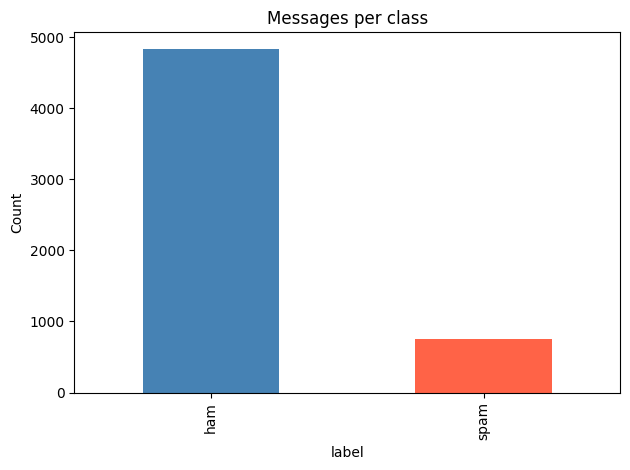

label
ham     0.866
spam    0.134
Name: count, dtype: float64


In [4]:
counts = df["label"].value_counts()
counts.plot(kind="bar", color=["steelblue", "tomato"], title="Messages per class")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

print((counts / len(df)).round(3))

## Message-level features

In [5]:
df["length"] = df["message"].str.len()
df["num_digits"] = df["message"].str.count(r"\d")
df["upper_ratio"] = df["message"].apply(lambda s: sum(c.isupper() for c in s) / max(len(s), 1))
df["has_url"] = df["message"].str.contains(r"http|www\.", case=False).astype(int)

df.groupby("label")[["length", "num_digits", "upper_ratio", "has_url"]].mean().round(3)

,length,num_digits,upper_ratio,has_url
label,,,,
ham,71.482,0.305,0.058,0.000
spam,138.671,15.813,0.111,0.143


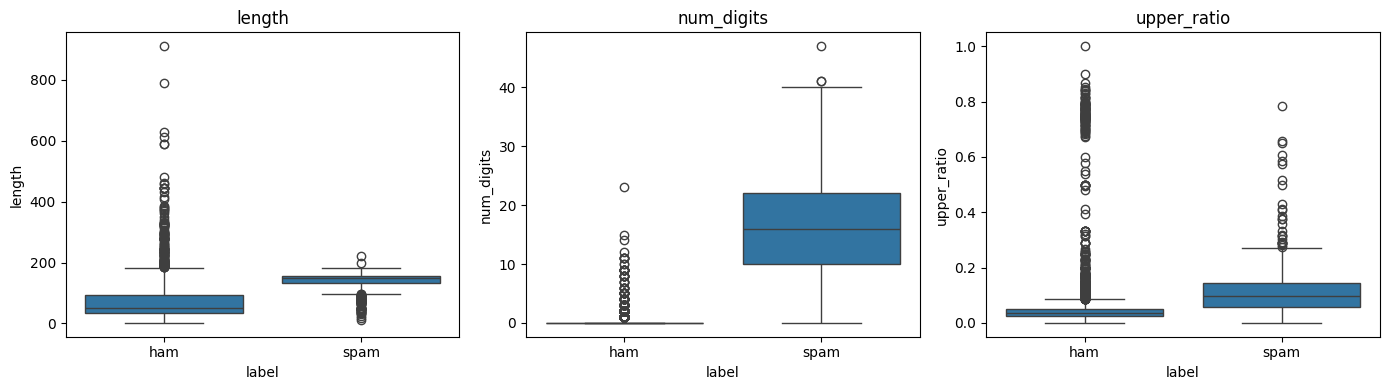

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["length", "num_digits", "upper_ratio"]):
    sns.boxplot(data=df, x="label", y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## Most frequent words

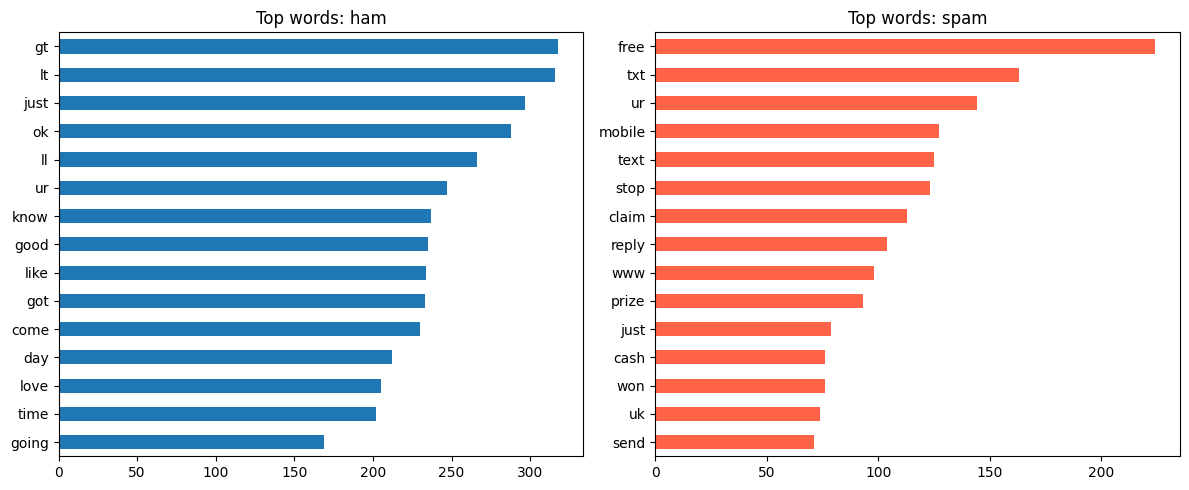

In [7]:
def top_words(texts, n=15):
    cv = CountVectorizer(stop_words="english")
    counts = cv.fit_transform(texts).sum(axis=0).A1
    return pd.Series(counts, index=cv.get_feature_names_out()).sort_values(ascending=False).head(n)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
top_words(df.loc[df["label"] == "ham", "message"]).plot(kind="barh", ax=axes[0], title="Top words: ham")
top_words(df.loc[df["label"] == "spam", "message"]).plot(kind="barh", ax=axes[1], title="Top words: spam", color="tomato")
for ax in axes:
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

In [8]:
df[df["label"] == "spam"].sample(5, random_state=1)[["message"]]

,message
5492,Marvel Mobile Play the official Ultimate Spider-man game (£4.50) on ur mobile right now. Text SPIDER to 83...
1146,"Thank you, winner notified by sms. Good Luck! No future marketing reply STOP to 84122 customer services 08..."
1699,"Free msg. Sorry, a service you ordered from 81303 could not be delivered as you do not have sufficient cre..."
2250,"Thanks for your ringtone order, ref number R836. Your mobile will be charged £4.50. Should your tone not a..."
5028,PRIVATE! Your 2003 Account Statement for shows 800 un-redeemed S.I.M. points. Call 08715203685 Identifier ...
